In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability --group=experiments --group=sandbox

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 8.4 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 

In [3]:
import time

# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
    )

# Importing the experiment author agent

In [4]:
import massi._experiments.author_agent as aa

In [5]:
import pathlib as pl

In [6]:
paper_1_path = pl.Path("papers/p1-a-geospatial-and-binomial-logistic-regression.pdf")

In [7]:
from massi.agents.interfaces import Config

In [8]:
e_config = Config(**{
    "model_url": "http://host.docker.internal:11434", 
    "model_name": "qwen3-embedding:0.6b"}
)
c_config = Config(**{
    "model_url": "http://host.docker.internal:11434", 
    "model_name": "lfm2.5-thinking:latest"}
)

In [9]:
%%time
aa_agent = aa.create_author_agent(paper_1_path, e_config, c_config)

CPU times: user 621 ms, sys: 40.1 ms, total: 661 ms
Wall time: 1min 50s


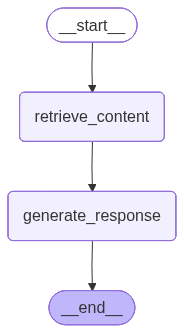

In [10]:
aa_agent

In [11]:
aa_agent.invoke({"question":"Could you please provide a brief description of the dataset that you describe your article?"})

{'question': 'Could you please provide a brief description of the dataset that you describe your article?',
 'context': 'GEOSPATIAL AND BINOMIAL LOGISTIC REGRESSION MODEL —Integr Environ Assess Manag 19, 2023 169\n 15513793, 2023, 1, Downloaded from https://onlinelibrary.wiley.com/doi/10.1002/ieam.4614 by Uva Universiteitsbibliotheek, Wiley Online Library on [13/03/2026]. See the Terms and Conditions (https://onlinelibrary.wiley.com/terms-and-conditions) on Wiley Online Library for rules of use; OA articles are governed by the applicable Creative Commons License\n\n166 Integr Environ Assess Manag 19, 2023 —OJHA ET AL .\n 15513793, 2023, 1, Downloaded from https://onlinelibrary.wiley.com/doi/10.1002/ieam.4614 by Uva Universiteitsbibliotheek, Wiley Online Library on [13/03/2026]. See the Terms and Conditions (https://onlinelibrary.wiley.com/terms-and-conditions) on Wiley Online Library for rules of use; OA articles are governed by the applicable Creative Commons License\n\nCollege of Eng